# Student Performance Predictor

## 1. Project Overview

### Objective
The objective of this project is to build a machine learning model that predicts a student's final grade (`G3`) using demographic, social, and academic information.

### Dataset
This project uses the Student Performance dataset from the UCI Machine Learning Repository, specifically the mathematics dataset (`student-mat.csv`).

### Problem Type
- **Machine Learning Task:** Supervised Learning
- **Problem Type:** Regression
- **Target Variable:** `G3` — final grade, on a scale from 0 to 20

### Project Workflow
1. Load and explore the dataset.
2. Perform exploratory data analysis (EDA).
3. Check data quality and understand the features.
4. Split the data into training and testing sets.
5. Preprocess numerical and categorical features.
6. Train Linear Regression and Random Forest models.
7. Evaluate and compare model performance.
8. Perform cross-validation and hyperparameter tuning.
9. Save and reload the complete preprocessing and prediction pipeline.
10. Generate predictions for new student data.

## 2. Import Libraries

In [77]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
import warnings
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
import joblib
from pathlib import Path


In [78]:
warnings.filterwarnings("ignore")
df = pd.read_csv("../data/student-mat.csv", sep=";")

## 3. Load Dataset

In [79]:
df.head()

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


## 4. Exploratory Data Analysis

In [80]:
df.shape

(395, 33)

In [81]:
for column in df.columns:
    print(column)

school
sex
age
address
famsize
Pstatus
Medu
Fedu
Mjob
Fjob
reason
guardian
traveltime
studytime
failures
schoolsup
famsup
paid
activities
nursery
higher
internet
romantic
famrel
freetime
goout
Dalc
Walc
health
absences
G1
G2
G3


In [82]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   school      395 non-null    str  
 1   sex         395 non-null    str  
 2   age         395 non-null    int64
 3   address     395 non-null    str  
 4   famsize     395 non-null    str  
 5   Pstatus     395 non-null    str  
 6   Medu        395 non-null    int64
 7   Fedu        395 non-null    int64
 8   Mjob        395 non-null    str  
 9   Fjob        395 non-null    str  
 10  reason      395 non-null    str  
 11  guardian    395 non-null    str  
 12  traveltime  395 non-null    int64
 13  studytime   395 non-null    int64
 14  failures    395 non-null    int64
 15  schoolsup   395 non-null    str  
 16  famsup      395 non-null    str  
 17  paid        395 non-null    str  
 18  activities  395 non-null    str  
 19  nursery     395 non-null    str  
 20  higher      395 non-null    str  
 21  inte

In [83]:
df.isnull().sum()
df.isnull()

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
390,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
391,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
392,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
393,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False


In [84]:
df.duplicated()
df.duplicated().sum()

np.int64(0)

In [85]:
df.describe()

,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
count,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000
mean,16.696203,2.749367,2.521519,1.448101,2.035443,0.334177,3.944304,3.235443,3.108861,1.481013,2.291139,3.554430,5.708861,10.908861,10.713924,10.415190
std,1.276043,1.094735,1.088201,0.697505,0.839240,0.743651,0.896659,0.998862,1.113278,0.890741,1.287897,1.390303,8.003096,3.319195,3.761505,4.581443
min,15.000000,0.000000,0.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,3.000000,0.000000,0.000000
25%,16.000000,2.000000,2.000000,1.000000,1.000000,0.000000,4.000000,3.000000,2.000000,1.000000,1.000000,3.000000,0.000000,8.000000,9.000000,8.000000
50%,17.000000,3.000000,2.000000,1.000000,2.000000,0.000000,4.000000,3.000000,3.000000,1.000000,2.000000,4.000000,4.000000,11.000000,11.000000,11.000000
75%,18.000000,4.000000,3.000000,2.000000,2.000000,0.000000,5.000000,4.000000,4.000000,2.000000,3.000000,5.000000,8.000000,13.000000,13.000000,14.000000
max,22.000000,4.000000,4.000000,4.000000,4.000000,3.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,75.000000,19.000000,19.000000,20.000000


In [86]:
df.dtypes

school          str
sex             str
age           int64
address         str
famsize         str
Pstatus         str
Medu          int64
Fedu          int64
Mjob            str
Fjob            str
reason          str
guardian        str
traveltime    int64
studytime     int64
failures      int64
schoolsup       str
famsup          str
paid            str
activities      str
nursery         str
higher          str
internet        str
romantic        str
famrel        int64
freetime      int64
goout         int64
Dalc          int64
Walc          int64
health        int64
absences      int64
G1            int64
G2            int64
G3            int64
dtype: object

## 5. Data Quality Checks

In [87]:
categorical_columns = df.select_dtypes(include="object").columns.to_list()
print(categorical_columns)
numerical_columns = df.select_dtypes(include="number").columns.to_list()
print(numerical_columns)

['school', 'sex', 'address', 'famsize', 'Pstatus', 'Mjob', 'Fjob', 'reason', 'guardian', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic']
['age', 'Medu', 'Fedu', 'traveltime', 'studytime', 'failures', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2', 'G3']


In [88]:
for col in categorical_columns:
    print(df[col].value_counts())


school
GP    349
MS     46
Name: count, dtype: int64
sex
F    208
M    187
Name: count, dtype: int64
address
U    307
R     88
Name: count, dtype: int64
famsize
GT3    281
LE3    114
Name: count, dtype: int64
Pstatus
T    354
A     41
Name: count, dtype: int64
Mjob
other       141
services    103
at_home      59
teacher      58
health       34
Name: count, dtype: int64
Fjob
other       217
services    111
teacher      29
at_home      20
health       18
Name: count, dtype: int64
reason
course        145
home          109
reputation    105
other          36
Name: count, dtype: int64
guardian
mother    273
father     90
other      32
Name: count, dtype: int64
schoolsup
no     344
yes     51
Name: count, dtype: int64
famsup
yes    242
no     153
Name: count, dtype: int64
paid
no     214
yes    181
Name: count, dtype: int64
activities
yes    201
no     194
Name: count, dtype: int64
nursery
yes    314
no      81
Name: count, dtype: int64
higher
yes    375
no      20
Name: count, dtype: int64

In [89]:
df['age'].describe()

count    395.000000
mean      16.696203
std        1.276043
min       15.000000
25%       16.000000
50%       17.000000
75%       18.000000
max       22.000000
Name: age, dtype: float64

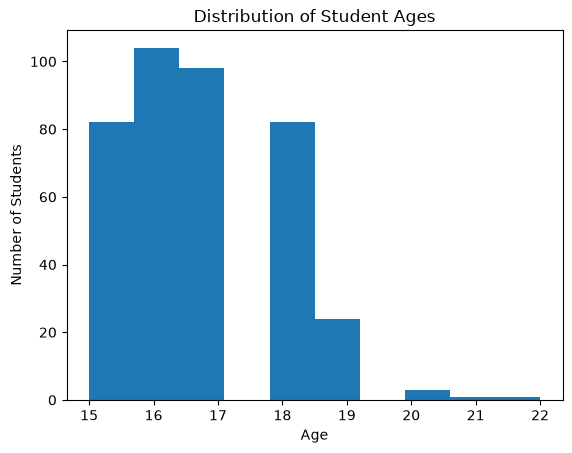

In [90]:
plt.hist(df["age"])
plt.xlabel("Age")
plt.ylabel("Number of Students")
plt.title("Distribution of Student Ages")
plt.show()

In [91]:
df[["studytime", "G3"]].corr()

,studytime,G3
studytime,1.00000,0.09782
G3,0.09782,1.00000


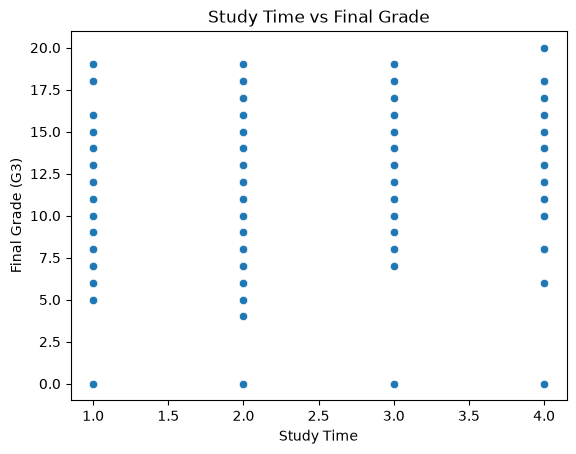

In [92]:
sns.scatterplot(data=df, x="studytime", y="G3")
plt.xlabel("Study Time")
plt.ylabel("Final Grade (G3)")
plt.title("Study Time vs Final Grade")
plt.show()

In [93]:
df[["studytime", "G3"]].corr()

,studytime,G3
studytime,1.00000,0.09782
G3,0.09782,1.00000


In [94]:
df[["G1", "G2", "G3"]].corr()

,G1,G2,G3
G1,1.000000,0.852118,0.801468
G2,0.852118,1.000000,0.904868
G3,0.801468,0.904868,1.000000


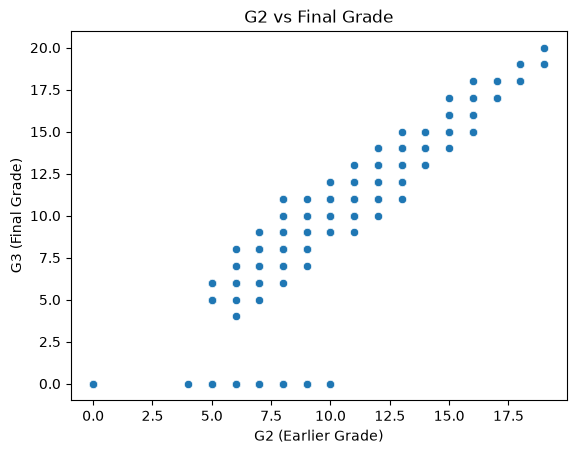

In [95]:
sns.scatterplot(data=df, x="G2", y="G3")

plt.xlabel("G2 (Earlier Grade)")
plt.ylabel("G3 (Final Grade)")
plt.title("G2 vs Final Grade")
plt.show()

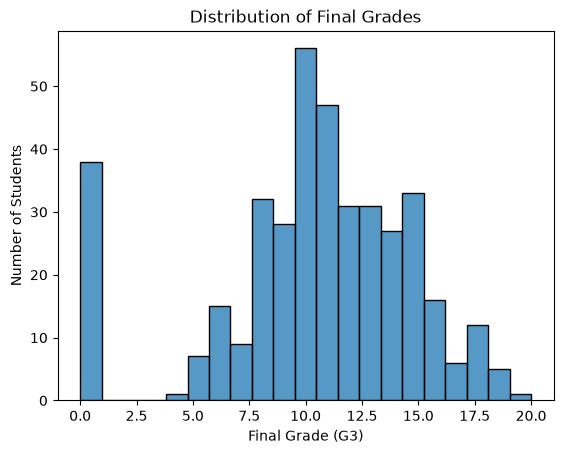

In [96]:
sns.histplot(data=df, x="G3", bins=21)

plt.xlabel("Final Grade (G3)")
plt.ylabel("Number of Students")
plt.title("Distribution of Final Grades")

plt.show()

In [97]:
df["G3"].value_counts().sort_index()

G3
0     38
4      1
5      7
6     15
7      9
8     32
9     28
10    56
11    47
12    31
13    31
14    27
15    33
16    16
17     6
18    12
19     5
20     1
Name: count, dtype: int64

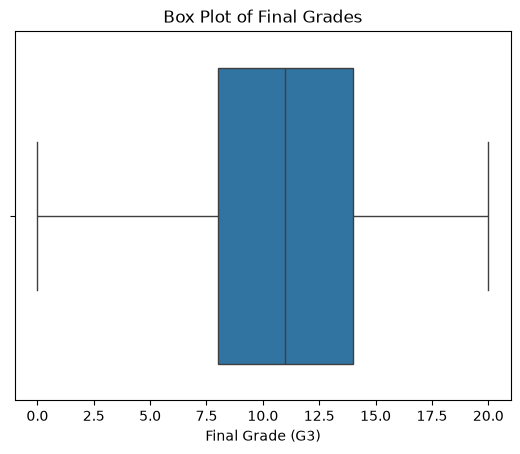

In [98]:
sns.boxplot(data=df, x="G3")

plt.xlabel("Final Grade (G3)")
plt.title("Box Plot of Final Grades")

plt.show()

## 6. Feature and Target Selection

In [99]:
X = df.drop("G3", axis = 1)
y = df["G3"]
print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (395, 32)
y shape: (395,)


## 7. Train-Test Split

In [100]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [101]:
print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

X_train: (316, 32)
X_test : (79, 32)
y_train: (316,)
y_test : (79,)


## 8. Data Preprocessing

In [102]:
numerical_features = X.select_dtypes(include="number").columns
categorical_features = X.select_dtypes(include="object").columns

print("Numerical:", numerical_features.tolist())
print("Categorical:", categorical_features.tolist())

Numerical: ['age', 'Medu', 'Fedu', 'traveltime', 'studytime', 'failures', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2']
Categorical: ['school', 'sex', 'address', 'famsize', 'Pstatus', 'Mjob', 'Fjob', 'reason', 'guardian', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic']


In [103]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

In [104]:
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)


In [105]:
print("Before preprocessing:", X_train.shape)
print("After preprocessing :", X_train_processed.shape)

print("Test before preprocessing:", X_test.shape)
print("Test after preprocessing :", X_test_processed.shape)

Before preprocessing: (316, 32)
After preprocessing : (316, 58)
Test before preprocessing: (79, 32)
Test after preprocessing : (79, 58)


## 9. Linear Regression

In [106]:
model_lr = LinearRegression()
model_lr.fit(X_train_processed,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](58,)","[-0.15, 0.09,-0.18,...,-0.08, 0.2 ,-0.2 ]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,10.56
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,58
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(41)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](58,)","[30.39,26.53,21.83,..., 0. , 0. , 0. ]"


In [107]:
y_pred = model_lr.predict(X_test_processed)
print(y_pred[:10])

[ 6.00160699 11.52847844  2.86643677  8.79663116  8.55310627 11.88964112
 19.09674195  7.17307901  7.4050707  12.31153657]


In [108]:
print(y_test.values[:10])

[10 12  5 10  9 13 18  6  0 14]


In [109]:
mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

rmse = mse ** 0.5

r2 = r2_score(y_test, y_pred)

print("MAE :", mae)
print("MSE :", mse)
print("RMSE:", rmse)
print("R²  :", r2)

MAE : 1.6466656197147496
MSE : 5.656642833231219
RMSE: 2.3783697847961363
R²  : 0.7241341236974024


## 10. Random Forest

In [110]:
model_rf = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

In [111]:
model_rf.fit(X_train_processed, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease o

In [112]:
y_pred_rf = model_rf.predict(X_test_processed)
print(y_pred_rf[:10])

[ 8.24 11.69  6.51  9.82  8.75 12.82 18.75  6.74  6.89 13.34]


In [113]:
mae_rf = mean_absolute_error(y_test, y_pred_rf)

mse_rf = mean_squared_error(y_test, y_pred_rf)

rmse_rf = mse_rf ** 0.5

r2_rf = r2_score(y_test, y_pred_rf)

print("MAE :", mae_rf)
print("MSE :", mse_rf)
print("RMSE:", rmse_rf)
print("R²  :", r2_rf)

MAE : 1.2137974683544304
MSE : 4.035386075949367
RMSE: 2.0088270398293044
R²  : 0.8032003524208421


## 11. Feature Importance

In [114]:
feature_names = preprocessor.get_feature_names_out()

print(len(feature_names))
print(feature_names[:20])

58
['num__age' 'num__Medu' 'num__Fedu' 'num__traveltime' 'num__studytime'
 'num__failures' 'num__famrel' 'num__freetime' 'num__goout' 'num__Dalc'
 'num__Walc' 'num__health' 'num__absences' 'num__G1' 'num__G2'
 'cat__school_GP' 'cat__school_MS' 'cat__sex_F' 'cat__sex_M'
 'cat__address_R']


In [115]:
preprocessor

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``

In [116]:
feature_importance = pd.DataFrame({
    "feature": feature_names,
    "importance": model_rf.feature_importances_
})

In [117]:
feature_importance = feature_importance.sort_values(
    by="importance",
    ascending=False
)

In [118]:
feature_importance.head(10)

,feature,importance
14,num__G2,0.792268
12,num__absences,0.109791
36,cat__reason_home,0.019529
0,num__age,0.010111
13,num__G1,0.006149
6,num__famrel,0.004639
8,num__goout,0.003959
35,cat__reason_course,0.003772
11,num__health,0.003525
4,num__studytime,0.003310


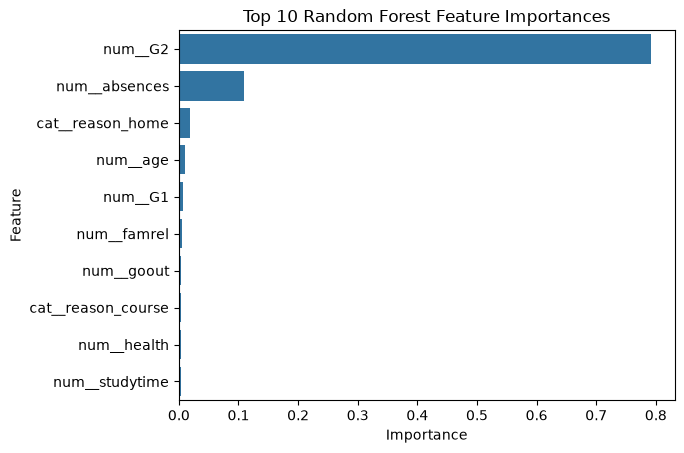

In [119]:
top_features = feature_importance.head(10)

sns.barplot(
    data=top_features,
    x="importance",
    y="feature"
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Top 10 Random Forest Feature Importances")

plt.show()

## 12. Cross-Validation and Hyperparameter Tuning

In [120]:
rf_200 = RandomForestRegressor(
    n_estimators=200,
    random_state=42
)

rf_200.fit(X_train_processed, y_train)

y_pred_200 = rf_200.predict(X_test_processed)

In [121]:
mae_200 = mean_absolute_error(y_test, y_pred_200)
mse_200 = mean_squared_error(y_test, y_pred_200)
rmse_200 = mse_200 ** 0.5
r2_200 = r2_score(y_test, y_pred_200)

print("MAE :", mae_200)
print("MSE :", mse_200)
print("RMSE:", rmse_200)
print("R²  :", r2_200)

MAE : 1.2005063291139242
MSE : 4.060087341772151
RMSE: 2.0149658413412745
R²  : 0.8019957092176414


In [122]:
rf_depth5 = RandomForestRegressor(
    n_estimators=100,
    max_depth=5,
    random_state=42
)

rf_depth5.fit(X_train_processed, y_train)

y_pred_depth5 = rf_depth5.predict(X_test_processed)

In [123]:
mae_depth5 = mean_absolute_error(y_test, y_pred_depth5)
mse_depth5 = mean_squared_error(y_test, y_pred_depth5)
rmse_depth5 = mse_depth5 ** 0.5
r2_depth5 = r2_score(y_test, y_pred_depth5)

print("MAE :", mae_depth5)
print("MSE :", mse_depth5)
print("RMSE:", rmse_depth5)
print("R²  :", r2_depth5)

MAE : 1.1881708480403104
MSE : 3.893850457742542
RMSE: 1.9732841806852206
R²  : 0.8101028294722971


In [124]:
rf_depth3 = RandomForestRegressor(
    n_estimators=100,
    max_depth=3,
    random_state=42
)

rf_depth3.fit(X_train_processed, y_train)

y_pred_depth3 = rf_depth3.predict(X_test_processed)

In [125]:
mae_depth3 = mean_absolute_error(y_test, y_pred_depth3)
mse_depth3 = mean_squared_error(y_test, y_pred_depth3)
rmse_depth3 = mse_depth3 ** 0.5
r2_depth3 = r2_score(y_test, y_pred_depth3)

print("MAE :", mae_depth3)
print("MSE :", mse_depth3)
print("RMSE:", rmse_depth3)
print("R²  :", r2_depth3)

MAE : 1.1301789736541337
MSE : 3.138210364950097
RMSE: 1.7714994679508367
R²  : 0.8469542486821058


In [126]:

rf_default_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(random_state=42))
])

cv_scores = cross_val_score(
    rf_default_pipeline,
    X_train,
    y_train,
    cv=5,
    scoring="neg_mean_absolute_error"
)

cv_mae = -cv_scores

print("MAE for each fold:", cv_mae)
print("Average MAE:", cv_mae.mean())


MAE for each fold: [0.9765625  0.78492063 0.87396825 1.02       0.87793651]
Average MAE: 0.9066775793650793


In [127]:

rf_depth3_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=100,
        max_depth=3,
        random_state=42
    ))
])

cv_scores_depth3 = cross_val_score(
    rf_depth3_pipeline,
    X_train,
    y_train,
    cv=5,
    scoring="neg_mean_absolute_error"
)

cv_mae_depth3 = -cv_scores_depth3

print("MAE for each fold:", cv_mae_depth3)
print("Average MAE:", cv_mae_depth3.mean())


MAE for each fold: [1.02752848 0.98036221 0.94291234 1.07651576 0.93578228]
Average MAE: 0.992620213523361


In [128]:
final_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(random_state=42))
])

param_grid = {
    "model__n_estimators": [100, 200],
    "model__max_depth": [None, 3, 5, 10]
}

grid_search = GridSearchCV(
    estimator=final_pipeline,
    param_grid=param_grid,
    cv=5,
    scoring="neg_mean_absolute_error",
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

print("Best parameters:", grid_search.best_params_)
print("Best CV MAE:", -grid_search.best_score_)

best_model = grid_search.best_estimator_

Best parameters: {'model__max_depth': 10, 'model__n_estimators': 100}
Best CV MAE: 0.9015959877279078


In [129]:
y_pred_best = best_model.predict(X_test)

mae_best = mean_absolute_error(y_test, y_pred_best)

mse_best = mean_squared_error(y_test, y_pred_best)

rmse_best = mse_best ** 0.5

r2_best = r2_score(y_test, y_pred_best)

print("Final Model Results")
print("-------------------")
print("MAE :", mae_best)
print("MSE :", mse_best)
print("RMSE:", rmse_best)
print("R²  :", r2_best)

Final Model Results
-------------------
MAE : 1.2117849294023806
MSE : 4.1155762497253825
RMSE: 2.028688307681932
R²  : 0.7992895994863243


## 13. Save and Reload the Pipeline

In [130]:
final_pipeline = best_model

models_dir = Path("../models")
models_dir.mkdir(parents=True, exist_ok=True)

model_path = models_dir / "student_performance_pipeline.joblib"

joblib.dump(final_pipeline, model_path)

print("Pipeline saved to:", model_path)

Pipeline saved to: ..\models\student_performance_pipeline.joblib


In [131]:
loaded_pipeline = joblib.load(model_path)

pipeline_predictions = final_pipeline.predict(X_test)
loaded_predictions = loaded_pipeline.predict(X_test)

print("Original predictions:", pipeline_predictions[:5])
print("Loaded predictions:  ", loaded_predictions[:5])

Original predictions: [ 8.20875    11.68125     6.51        9.80294899  8.61148567]
Loaded predictions:   [ 8.20875    11.68125     6.51        9.80294899  8.61148567]


In [132]:
print(
    "Predictions match:",
    np.allclose(pipeline_predictions, loaded_predictions)
)

Predictions match: True


## 14. Predict for a New Student

In [133]:
new_student = X.iloc[[0]].copy()

new_student.loc[:, "age"] = 17
new_student.loc[:, "studytime"] = 3
new_student.loc[:, "absences"] = 4
new_student.loc[:, "G1"] = 14
new_student.loc[:, "G2"] = 15

new_student

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,romantic,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2
0,GP,F,17,U,GT3,A,4,4,at_home,teacher,...,no,4,3,4,1,1,3,4,14,15


In [134]:
predicted_grade = loaded_pipeline.predict(new_student)

print(f"Predicted final grade (G3): {predicted_grade[0]:.2f}/20")

Predicted final grade (G3): 15.17/20


In [135]:
test_predictions = loaded_pipeline.predict(X_test)

comparison = pd.DataFrame({
    "Actual G3": y_test.values,
    "Predicted G3": test_predictions
})

comparison["Absolute Error"] = abs(
    comparison["Actual G3"] - comparison["Predicted G3"]
)

comparison.head(10)

,Actual G3,Predicted G3,Absolute Error
0,10,8.208750,1.791250
1,12,11.681250,0.318750
2,5,6.510000,1.510000
3,10,9.802949,0.197051
4,9,8.611486,0.388514
5,13,12.800000,0.200000
6,18,18.780000,0.780000
7,6,6.770000,0.770000
8,0,7.052333,7.052333
9,14,13.263333,0.736667


## 15. Conclusion and Limitations

### Conclusion

This project demonstrates an end-to-end supervised machine learning workflow for predicting students' final mathematics grades using the UCI Student Performance dataset.

The project includes data exploration, preprocessing of numerical and categorical features, model training, evaluation, cross-validation, hyperparameter tuning, and saving a complete prediction pipeline.

Linear Regression was used as a baseline model, while Random Forest Regression was used to capture potentially more complex relationships in the data. The preprocessing and model were combined into a single scikit-learn pipeline, which was saved and successfully reloaded for predictions.

### Limitations

1. **Small dataset:** The mathematics dataset contains only 395 student records, which limits the amount of data available for training and evaluation.
2. **Limited generalization:** Results on this dataset may not generalize to students from other schools, regions, or educational systems.
3. **Earlier grades as input:** The model uses `G1` and `G2` to predict `G3`. Its predictions therefore assume earlier-period grades are available.
4. **Prediction uncertainty:** Predictions are estimates and may differ substantially from actual grades for individual students.
5. **Feature importance:** Feature importance indicates how a model uses features for prediction; it does not establish causation.
6. **Evaluation limitations:** The test set was examined during multiple model comparisons. Therefore, it should not be treated as a completely untouched final evaluation set.

### Future Improvements

- Evaluate the model on a larger, independent dataset.
- Improve evaluation methodology by keeping a final test set untouched during model selection.
- Experiment with additional regression models and compare them using cross-validation.
- Build a simple user interface for entering student information and viewing predictions.